# **Experiment Notebook**

**Weather Hazard Category (WHC) – 7-day multiclass classification**

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
# <Student to fill this section>
student_name = "Arsh Ashfaqhusein Mansuri"
student_id = "25522436"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
# <Student to fill this section>
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Custom package from AT1 (shiftguard), extended for AT2 and published to TestPyPI
# %pip install -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple shiftguard
import shiftguard
from shiftguard import adversarial_auc
from shiftguard.weather import (
    build_features, ClimatologyBaseline, persistence_forecast, scores_table,
    compute_whi, whi_to_category, WHC_LABELS, classification_scores,
)

from weather_experiments.config import (
    RAW_DATA_DIR, PROCESSED_DATA_DIR, MODELS_DIR, FIGURES_DIR, REPORTS_DIR,
    PRODUCTION_CUTOFF, VAL_START, TEST_START, SEED,
)
from weather_experiments.features import build_model_table, select_groups, EXCLUDED_BASE_VARS

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("shiftguard", shiftguard.__version__)
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.utils.class_weight import compute_sample_weight

HORIZON = 7
TARGETS = ["target_whc_t7"]
LABELS = [0, 1, 2, 3]

2026-09-27 17:35:14.629 | INFO     | weather_experiments.config:<module>:11 - PROJ_ROOT path is: /Users/arsh/Desktop/Adv_ML_AT2/36120-26SP-AT2-25522436-experiments


shiftguard 0.2.0


---
## A. Project Description


In [8]:
# <Student to fill this section>
business_use_case_description = """
Open-Meteo is adding AI services to its weather platform. This experiment builds a service that classifies the Weather Hazard Category (Low / Moderate / High / Extreme Risk) for Sydney exactly 7 days ahead. A week of lead time is what infrastructure operators, transport providers, event organisers, insurers and emergency-planning teams need to schedule maintenance, crews and contingency plans around potentially disruptive rain, wind and cloud.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
# <Student to fill this section>
business_objectives = """
Goal: predict the hazard class at t+7 more usefully than the seasonal average or "same as today", measured with macro-F1 so every class counts equally.
A correct early warning of a High/Extreme day lets operators prepare (extra crews, rescheduling, public messaging); a missed severe day (false negative) is far more costly than a false alarm, which only wastes preparation effort. Conversely, frequent false alarms erode trust. The business objective is therefore as much about honestly quantifying what can be predicted a week ahead as about the headline score.
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
# <Student to fill this section>
stakeholders_expectations_explanations = """
- Operations and planning teams (transport, utilities, events, councils): a simple risk label a week ahead, with known reliability for each class.
- Emergency and safety stakeholders: must not treat this model as a warning system; official warnings remain the Bureau of Meteorology's responsibility.
- Open-Meteo platform team: a transparent, versioned, reproducible service (/model-metadata exposes algorithm, features, importance and test metrics).
Predictions are consumed per request via /predict/category/weather_hazard?date=YYYY-MM-DD.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## B. Experiment Hypothesis

In [14]:
# <Student to fill this section>
experiment_hypothesis = """
H1: A class-weighted gradient-boosting classifier using same-day, lag, rolling and calendar features will achieve a higher macro-F1 on the 2023-2025 test set than the monthly climatology baseline (most common class per target month) for WHC at t+7.
H2: The same model will achieve non-zero recall on High Risk days in the test set.
Both are tested once on the test set after all modelling decisions were made on training/validation data.
"""

In [15]:
# Do not modify this code
print_tile(size="h3", key='experiment_hypothesis', value=experiment_hypothesis)

---
## C. Data Understanding

### C.1   Load Raw Data


In [16]:
# <Student to fill this section>
# Built by `uv run python -m weather_experiments.dataset`: hourly Open-Meteo archive data (1980-2025)
# for Sydney, aggregated to daily values. Nothing on/after the production cut-off is loaded.
daily_df = pd.read_parquet(PROCESSED_DATA_DIR / "sydney_daily.parquet")
assert daily_df.index.max() < pd.Timestamp(PRODUCTION_CUTOFF)
daily_df.head()

,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,snowfall,wind_gusts_10m,temperature_2m_max,temperature_2m_min,precipitation_hours,...,shortwave_radiation,wind_u,wind_v,cci,whi,whc,target_cci_t1,target_cci_t2,target_cci_t3,target_whc_t7
date,,,,,,,,,,,,,,,,,,,,,
1980-01-01,21.204167,85.291667,15.212500,99.583333,14.3,0.0,45.7,23.1,19.4,15.0,...,137.958333,-5.036943,13.250119,56.873437,48.245000,1,52.284375,60.406250,64.096875,1
1980-01-02,20.158333,88.708333,10.441667,98.291667,18.8,0.0,31.3,21.9,19.3,24.0,...,106.333333,-4.057265,8.168493,52.284375,48.585000,1,60.406250,64.096875,81.223958,0
1980-01-03,21.587500,82.000000,7.625000,90.875000,15.4,0.0,35.6,23.6,19.6,5.0,...,194.958333,-7.082028,0.211677,60.406250,44.420000,1,64.096875,81.223958,75.800521,1
1980-01-04,22.041667,86.583333,9.541667,72.666667,13.5,0.0,48.6,25.7,20.2,11.0,...,187.958333,0.714975,-0.222901,64.096875,42.630000,1,81.223958,75.800521,72.734896,0
1980-01-05,21.200000,72.041667,12.041667,51.958333,0.0,0.0,37.1,23.9,19.0,0.0,...,323.541667,-0.760570,10.584489,81.223958,21.841667,0,75.800521,72.734896,76.068750,0


### C.2 Define Target variable

In [17]:
# <Student to fill this section>
# The target formula lives in the shiftguard package so the notebook and the API share it.
print(inspect.getsource(compute_whi))
print(inspect.getsource(whi_to_category))

def compute_whi(df: pd.DataFrame) -> pd.Series:
    """Compute the Weather Hazard Index (0-100) from daily aggregated weather.

    Expects daily total ``precipitation`` and ``snowfall``, daily maximum ``wind_gusts_10m``
    and daily mean ``cloud_cover`` and ``temperature_2m``.
    """
    rain = np.minimum(df["precipitation"] / 30, 1)
    wind = np.minimum(df["wind_gusts_10m"] / 100, 1)
    cloud = np.minimum(df["cloud_cover"] / 100, 1)
    snow = np.minimum(df["snowfall"] / 15, 1)
    temp = np.minimum((df["temperature_2m"] - 22).abs() / 25, 1)
    whi = 100 * (0.30 * rain + 0.30 * wind + 0.20 * cloud + 0.10 * snow + 0.10 * temp)
    return whi.rename("whi")

def whi_to_category(whi: pd.Series) -> pd.Series:
    """Convert Weather Hazard Index values to class labels 0-3.

    Bins are closed on the left, so 25 is Moderate, 50 is High and 75 is Extreme.
    Missing WHI values stay missing.
    """
    bins = [-np.inf, *WHI_THRESHOLDS, np.inf]
    category = pd.cut(whi, bins=bins, rig

In [18]:
# <Student to fill this section>
target_definition_explanations = """
The WHC follows the brief exactly. Hourly data is aggregated to daily total precipitation and snowfall, daily maximum wind gust and daily mean cloud cover and temperature. Five hazard scores capped at 1 are computed (rain /30 mm, gusts /100 km/h, cloud /100%, snow /15 cm, |temperature - 22| /25 °C) and combined with weights 0.30/0.30/0.20/0.10/0.10 into the WHI (0-100). The WHI is cut at 25/50/75 into classes 0-3 with left-closed intervals, so a WHI of exactly 25 is Moderate (tested in the package).
The target is the class 7 days later (shift -7). As required, the model predicts the class label, not the continuous WHI. The formula lives in shiftguard.weather so the notebook, unit tests and API share it.
"""

In [19]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable


In [20]:
# <Student to fill this section>
daily_df["whi"] = compute_whi(daily_df)
daily_df["whc"] = whi_to_category(daily_df["whi"])
daily_df["target_whc_t7"] = daily_df["whc"].shift(-7)

target_name = 'target_whc_t7'
# The last 7 input dates have no target: their t+7 date falls in 2026 (production data, never loaded).
daily_df[["whi", "whc", target_name]].tail(8)

,whi,whc,target_whc_t7
date,,,
2025-12-24,20.843333,0,1
2025-12-25,37.226667,1,<NA>
2025-12-26,37.203333,1,<NA>
2025-12-27,23.973333,0,<NA>
2025-12-28,30.118333,1,<NA>
2025-12-29,17.741667,0,<NA>
2025-12-30,21.613333,0,<NA>
2025-12-31,31.441667,1,<NA>


### C.4 Explore Target variable

,days,share_%
whc,,
Low Risk,9366,55.74
Moderate Risk,6957,41.41
High Risk,462,2.75
Extreme Risk,17,0.1


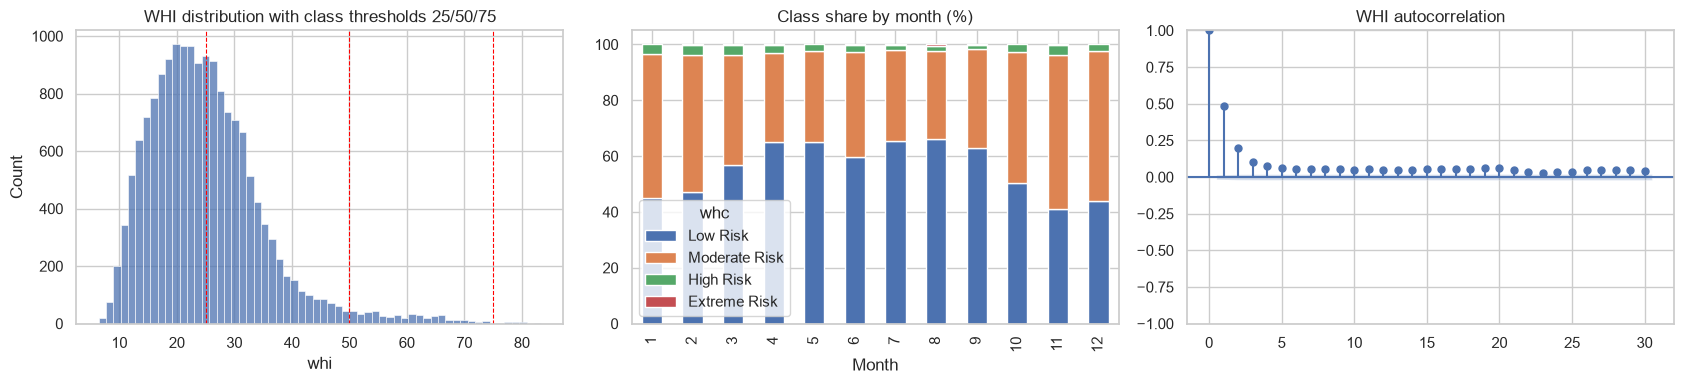

In [21]:
# <Student to fill this section>
whi, whc = daily_df["whi"], daily_df["whc"]
class_share = pd.DataFrame({
    "days": whc.value_counts().sort_index(),
    "share_%": (whc.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=WHC_LABELS)
display(class_share)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(whi, bins=60, ax=axes[0])
for x in (25, 50, 75):
    axes[0].axvline(x, ls="--", c="red", lw=0.8)
axes[0].set_title("WHI distribution with class thresholds 25/50/75")
(pd.crosstab(whc.index.month, whc, normalize="index") * 100).rename(columns=WHC_LABELS).plot(
    kind="bar", stacked=True, ax=axes[1], title="Class share by month (%)", xlabel="Month")
plot_acf(whi, lags=30, ax=axes[2]); axes[2].set_title("WHI autocorrelation")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_target_overview.png", dpi=120); plt.show()

In [22]:
# <Student to fill this section>
print("WHI autocorrelation at lag 1/2/3/7:", [round(whi.autocorr(lag), 2) for lag in (1, 2, 3, 7)])
split_of = pd.cut(daily_df.index.year, [0, 2019, 2022, 2025], labels=["train 1980-2019", "val 2020-2022", "test 2023-2025"])
display(pd.crosstab(split_of, whc.map(WHC_LABELS)))
hazards = pd.DataFrame({
    "RainHazard": (daily_df["precipitation"] / 30).clip(upper=1),
    "WindHazard": (daily_df["wind_gusts_10m"] / 100).clip(upper=1),
    "CloudHazard": (daily_df["cloud_cover"] / 100).clip(upper=1),
    "SnowHazard": (daily_df["snowfall"] / 15).clip(upper=1),
    "TempHazard": ((daily_df["temperature_2m"] - 22).abs() / 25).clip(upper=1),
})
weights = pd.Series({"RainHazard": .30, "WindHazard": .30, "CloudHazard": .20, "SnowHazard": .10, "TempHazard": .10})
contrib = hazards * weights * 100
pd.DataFrame({"mean_contribution_all_days": contrib.mean(),
              "mean_contribution_high_or_extreme_days": contrib[whc >= 2].mean()}).round(2)

WHI autocorrelation at lag 1/2/3/7: [np.float64(0.49), np.float64(0.2), np.float64(0.1), np.float64(0.05)]


whc,Extreme Risk,High Risk,Low Risk,Moderate Risk
row_0,,,,
train 1980-2019,11,349,8366,5884
val 2020-2022,5,66,481,544
test 2023-2025,1,47,519,529


,mean_contribution_all_days,mean_contribution_high_or_extreme_days
RainHazard,1.91,23.94
WindHazard,11.56,15.60
CloudHazard,9.53,18.43
SnowHazard,0.00,0.00
TempHazard,2.06,1.94


In [23]:
# <Student to fill this section>
target_distribution_explanations = """
The classes are highly imbalanced: Low 55.7%, Moderate 41.4%, High 2.75% (462 days) and Extreme 0.10% (17 days in 46 years). Only 11 Extreme days are in training, 5 in validation and 1 in test, so the Extreme class is essentially unlearnable and its test recall is based on one day.
The WHI has very short memory: autocorrelation 0.49 at lag 1, 0.10 at lag 3 and 0.05 at lag 7 - the value one week ahead is almost unrelated to today's. Class shares also drift over time: Moderate and High days are more common in 2020-2025, partly because of wet La Niña years and partly because of the 2017 data-source change that raised gust values. On High/Extreme days the WHI is driven by rain (mean contribution 23.9 points), cloud (18.4) and wind (15.6); snow never contributes and temperature very little.
"""

In [24]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `wind_gusts_10m`

daily max, km/h – 30% of the WHI weight

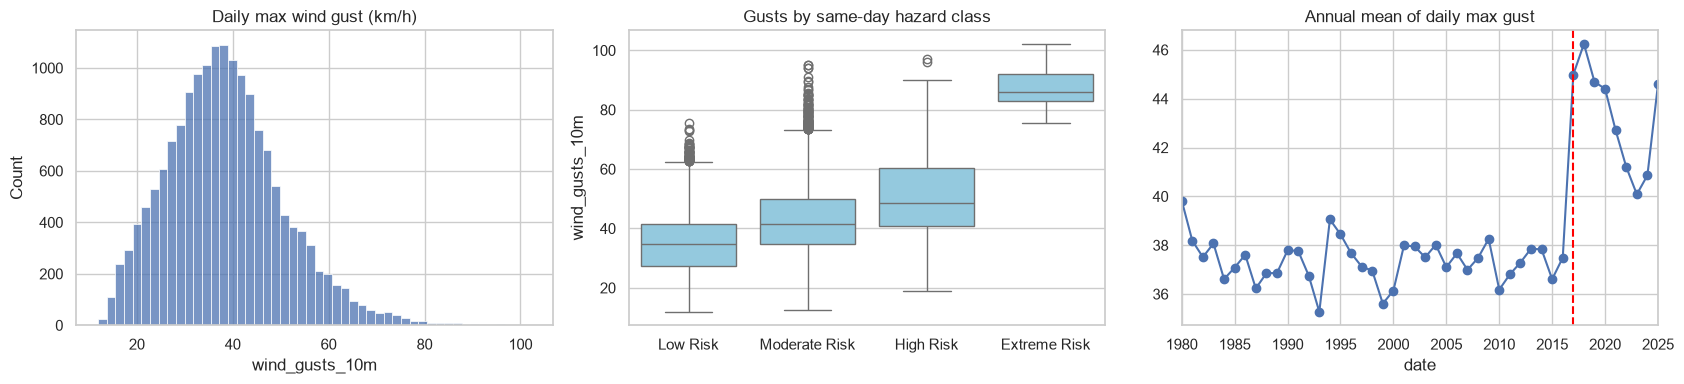

count    16802.00
mean        38.53
std         12.11
min         11.90
25%         30.20
50%         37.80
75%         45.40
max        102.20
Name: wind_gusts_10m, dtype: float64

In [25]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(daily_df["wind_gusts_10m"], bins=50, ax=axes[0]); axes[0].set_title("Daily max wind gust (km/h)")
sns.boxplot(x=whc.map(WHC_LABELS), y=daily_df["wind_gusts_10m"], ax=axes[1], color="skyblue", order=list(WHC_LABELS.values()))
axes[1].set(title="Gusts by same-day hazard class", xlabel="")
daily_df["wind_gusts_10m"].resample("YE").mean().plot(ax=axes[2], marker="o", title="Annual mean of daily max gust")
axes[2].axvline(pd.Timestamp("2017-01-01"), c="red", ls="--")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_gusts.png", dpi=120); plt.show()
daily_df["wind_gusts_10m"].describe().round(2)

In [26]:
# <Student to fill this section>
# How much does each hazard input still relate to the class 7 days later?
inputs = ["precipitation", "wind_gusts_10m", "cloud_cover", "temperature_2m", "surface_pressure"]
pd.DataFrame({"same_day_whi": daily_df[inputs].corrwith(daily_df["whi"]),
              "whi_7_days_later": daily_df[inputs].corrwith(daily_df["whi"].shift(-7))}).round(3)

,same_day_whi,whi_7_days_later
precipitation,0.727,0.017
wind_gusts_10m,0.461,0.069
cloud_cover,0.801,0.061
temperature_2m,0.102,0.123
surface_pressure,-0.162,-0.030


In [27]:
# <Student to fill this section>
feature_1_insights = """
Daily maximum gusts average 38.5 km/h (range 12-102). Gusts increase clearly with the hazard class and carry 30% of the WHI weight. The annual series shows the 2017 step change (mean 37.4 -> 43.3 km/h), which is a data-source artefact and a drift risk for any model trained on earlier years. Gust autocorrelation is low (0.44 at lag 1, 0.19 at lag 7), so today's gusts say little about gusts in a week.
"""

In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `precipitation`

daily total, mm – 30% of the WHI weight

Dry days (<=0.1 mm): 56.5% | days >= 30 mm (RainHazard = 1): 1.0%


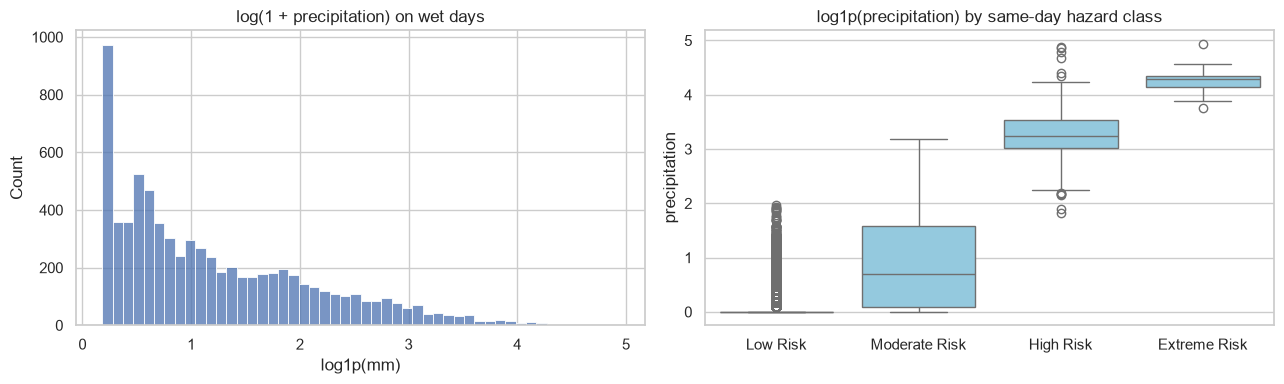

date
2020-02-09    138.4
1992-02-09    130.0
1990-02-03    128.3
1987-11-11    118.0
1990-02-04    105.6
Name: precipitation, dtype: float64

In [29]:
# <Student to fill this section>
precip = daily_df["precipitation"]
print(f"Dry days (<=0.1 mm): {(precip <= 0.1).mean():.1%} | days >= 30 mm (RainHazard = 1): {(precip >= 30).mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log1p(precip[precip > 0.1]), bins=50, ax=axes[0]); axes[0].set(title="log(1 + precipitation) on wet days", xlabel="log1p(mm)")
sns.boxplot(x=whc.map(WHC_LABELS), y=np.log1p(precip), ax=axes[1], color="skyblue", order=list(WHC_LABELS.values()))
axes[1].set(title="log1p(precipitation) by same-day hazard class", xlabel="")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_precipitation.png", dpi=120); plt.show()
precip.sort_values(ascending=False).head(5).round(1)

In [30]:
# <Student to fill this section>
feature_2_insights = """
Precipitation is zero-inflated (56.5% dry days) and heavy-tailed (max 138 mm); only a small share of days reach 30 mm, where RainHazard is capped at 1. Rain is the dominant driver of High/Extreme days. Its autocorrelation almost vanishes after two days (0.02 at lag 7) and its correlation with the WHI 7 days later is close to zero, so single-day rain is not predictive at t+7; only longer rolling totals (wet spells, seasonal state) carry some signal.
"""

In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `cloud_cover`

daily mean, % – 20% of the WHI weight

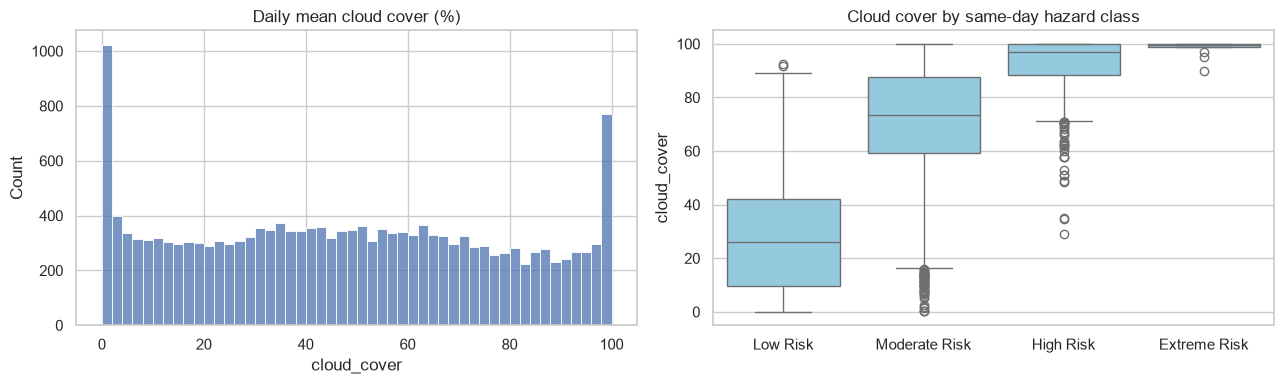

count    16802.00
mean        47.66
std         30.14
min          0.00
25%         22.00
50%         47.04
75%         72.17
max        100.00
Name: cloud_cover, dtype: float64

In [32]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(daily_df["cloud_cover"], bins=50, ax=axes[0]); axes[0].set_title("Daily mean cloud cover (%)")
sns.boxplot(x=whc.map(WHC_LABELS), y=daily_df["cloud_cover"], ax=axes[1], color="skyblue", order=list(WHC_LABELS.values()))
axes[1].set(title="Cloud cover by same-day hazard class", xlabel="")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_cloud.png", dpi=120); plt.show()
daily_df["cloud_cover"].describe().round(2)

In [33]:
# <Student to fill this section>
# High/Extreme days need several hazards at once: rain + gusts + cloud.
daily_df.loc[whc >= 2, ["precipitation", "wind_gusts_10m", "cloud_cover", "temperature_2m", "whi"]].describe().round(1)

,precipitation,wind_gusts_10m,cloud_cover,temperature_2m,whi
count,479.0,479.0,479.0,479.0,479.0
mean,30.0,52.0,92.2,17.2,59.9
std,17.6,15.1,11.5,3.3,7.2
min,5.2,19.1,29.0,8.8,50.0
25%,19.5,41.0,88.8,14.6,53.9
50%,25.1,49.3,97.3,17.4,59.0
75%,34.7,61.9,99.8,20.0,64.9
max,138.4,102.2,100.0,24.5,83.4


In [34]:
# <Student to fill this section>
feature_n_insights = """
Cloud cover (mean 47.7%, spread across the full 0-100% range) contributes 20% of the WHI and rises clearly with the hazard class. High/Extreme days typically combine heavy rain, strong gusts and near-total cloud cover (see the summary table), so severe days require several hazards at once - a rare conjunction that is hard to foresee a week ahead from local observations alone.
"""

In [35]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.8 Explore Remaining Features

temperature_2m, snowfall (0 on every day in Sydney) and the extra predictors

> You can add more cells related to other feeatures in this section

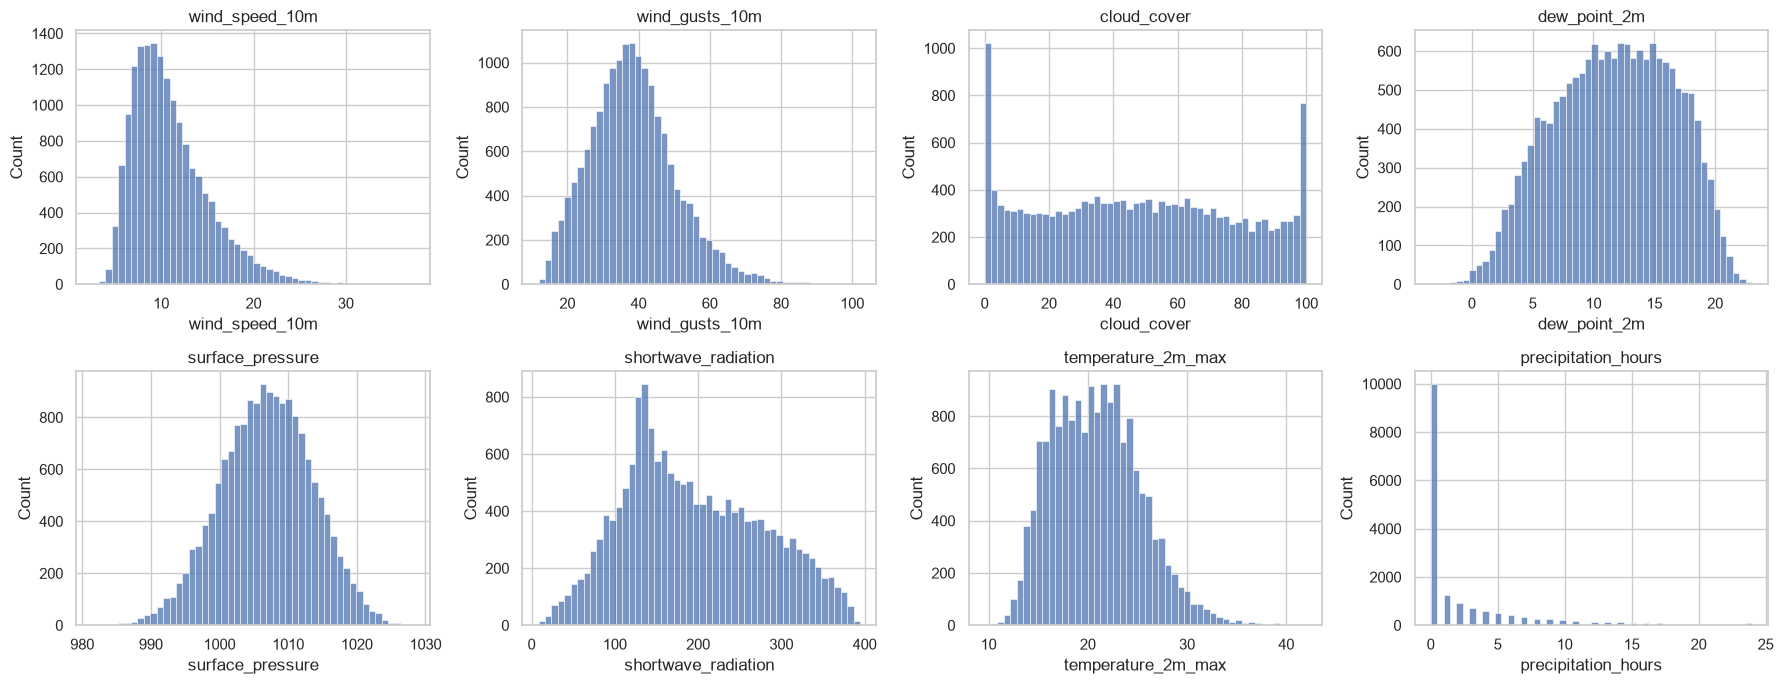

,count,mean,std,min,25%,50%,75%,max
wind_speed_10m,16802.0,11.01,4.21,2.55,7.94,10.13,13.18,37.39
wind_gusts_10m,16802.0,38.53,12.11,11.90,30.20,37.80,45.40,102.20
cloud_cover,16802.0,47.66,30.14,0.00,22.00,47.04,72.17,100.00
dew_point_2m,16802.0,11.65,4.85,-3.38,7.95,11.84,15.53,23.05
surface_pressure,16802.0,1006.82,6.69,981.50,1002.27,1006.91,1011.48,1028.32
shortwave_radiation,16802.0,194.01,83.55,8.38,130.42,182.44,257.92,394.50
temperature_2m_max,16802.0,20.84,4.46,9.60,17.30,20.60,23.80,42.00
precipitation_hours,16802.0,2.52,4.69,0.00,0.00,0.00,3.00,24.00


In [36]:
# <Student to fill this section>
other_vars = ["wind_speed_10m", "wind_gusts_10m", "cloud_cover", "dew_point_2m",
              "surface_pressure", "shortwave_radiation", "temperature_2m_max", "precipitation_hours"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, var in zip(axes.ravel(), other_vars):
    sns.histplot(daily_df[var], bins=50, ax=ax)
    ax.set_title(var)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_other_features.png", dpi=120); plt.show()
daily_df[other_vars].describe().T.round(2)

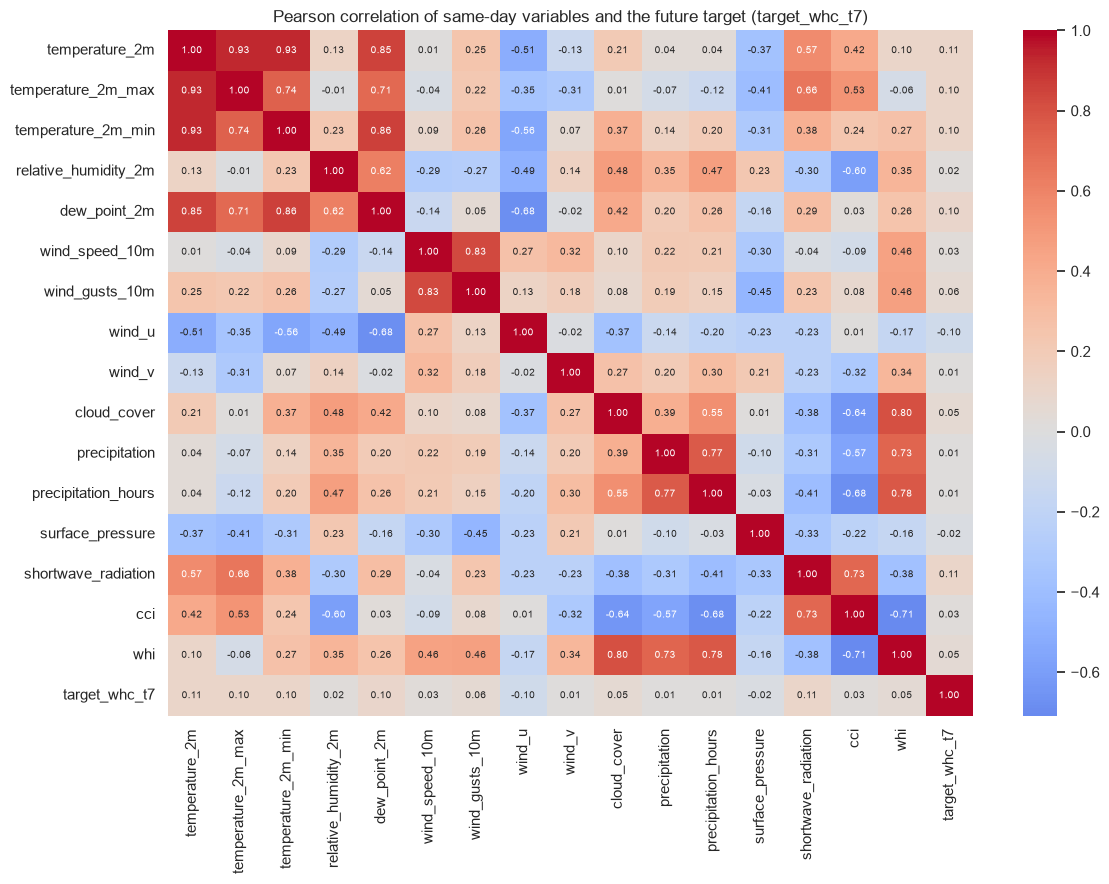

In [37]:
# <Student to fill this section>
base_vars = ["temperature_2m", "temperature_2m_max", "temperature_2m_min", "relative_humidity_2m",
             "dew_point_2m", "wind_speed_10m", "wind_gusts_10m", "wind_u", "wind_v", "cloud_cover",
             "precipitation", "precipitation_hours", "surface_pressure", "shortwave_radiation",
             "cci", "whi", "target_whc_t7"]
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(daily_df[base_vars].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Pearson correlation of same-day variables and the future target (target_whc_t7)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_correlation_heatmap.png", dpi=120); plt.show()

---
## D. Feature Selection



### D.1 Approach "Correlation and Mutual Information with the Target"

In [38]:
# <Student to fill this section>
model_table, all_features = build_model_table(daily_df)
print(len(all_features), "candidate features built by shiftguard.build_features (details in section F)")
# Selection statistics are computed on the training period only so validation/test stay unseen.
sel = model_table.loc[model_table.index < VAL_START].dropna(subset=["target_whc_t7"])
future_whi = daily_df["whi"].shift(-7).reindex(sel.index)
rank = pd.DataFrame({
    "abs_pearson_vs_future_whi": sel[all_features].corrwith(future_whi).abs(),
    "mutual_info_vs_class": mutual_info_classif(sel[all_features], sel["target_whc_t7"].astype(int), random_state=SEED),
}, index=all_features)
group_of = {c: g for g in ["raw", "lags", "rolling", "calendar"] for c in select_groups(all_features, [g])}
rank["group"] = rank.index.map(group_of)
rank.sort_values("mutual_info_vs_class", ascending=False).head(15).round(4)

161 candidate features built by shiftguard.build_features (details in section F)


,abs_pearson_vs_future_whi,mutual_info_vs_class,group
month_cos,0.1786,0.0224,calendar
wind_gusts_10m_roll14_mean,0.1391,0.0219,rolling
shortwave_radiation_roll14_mean,0.1606,0.0205,rolling
precipitation_roll30_sum,0.0148,0.0191,rolling
shortwave_radiation_roll7_mean,0.1578,0.0189,rolling
wind_u,0.1046,0.0175,raw
wind_u_roll7_mean,0.1275,0.0175,rolling
doy_cos,0.1742,0.0161,calendar
dew_point_2m_roll30_mean,0.0877,0.0154,rolling
temperature_2m_roll3_mean,0.1247,0.0154,rolling


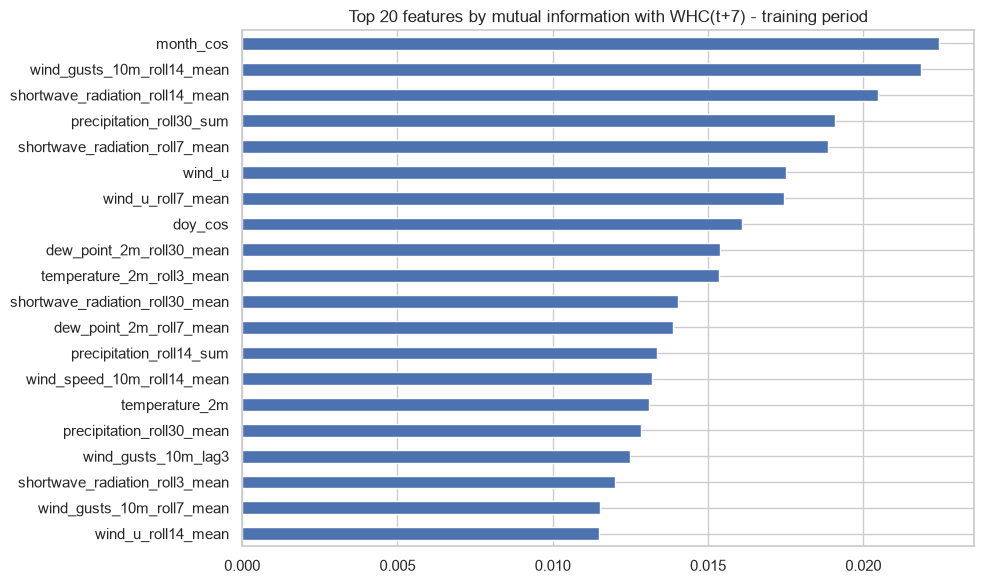

abs_pearson_vs_future_whi         mutual_info_vs_class        
                              mean     max                 mean     max
group                                                                  
calendar                    0.1006  0.1786               0.0127  0.0224
lags                        0.0571  0.1277               0.0031  0.0125
raw                         0.0594  0.1231               0.0052  0.0175
rolling                     0.0747  0.1716               0.0066  0.0219

In [39]:
# <Student to fill this section>
fig, ax = plt.subplots(figsize=(10, 6))
rank.sort_values("mutual_info_vs_class").tail(20)["mutual_info_vs_class"].plot(kind="barh", ax=ax, title="Top 20 features by mutual information with WHC(t+7) - training period")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_mutual_information.png", dpi=120); plt.show()
rank.groupby("group")[["abs_pearson_vs_future_whi", "mutual_info_vs_class"]].agg(["mean", "max"]).round(4)

In [40]:
# <Student to fill this section>
feature_selection_1_insights = """
Mutual information with the t+7 class and Pearson correlation with the future WHI were computed on the training period only. All values are small (MI at most 0.022, |r| at most 0.18), confirming the weak predictability. The most informative features are seasonal (month_cos, doy_cos) and slowly varying regime indicators: 14-30-day rolling means of gusts, radiation and dew point and the 30-day rainfall total. Same-day values of the hazard drivers are much less informative a week ahead than for next-day prediction.
"""

In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Permutation Importance from a Tree Ensemble (validation set)"

In [42]:
# <Student to fill this section>
val_sel = model_table.loc[(model_table.index >= VAL_START) & (model_table.index < TEST_START)].dropna(subset=["target_whc_t7"])
def rf_probe():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                  class_weight="balanced", n_jobs=-1, random_state=SEED)
probe = rf_probe().fit(sel[all_features], sel["target_whc_t7"].astype(int))
perm = permutation_importance(probe, val_sel[all_features], val_sel["target_whc_t7"].astype(int),
                              scoring="f1_macro", n_repeats=3, random_state=SEED)
perm_imp = pd.Series(perm.importances_mean, index=all_features).sort_values(ascending=False)
print("Features whose shuffling does not reduce validation macro-F1:", int((perm_imp <= 0).sum()), "of", len(perm_imp))
perm_imp.groupby(perm_imp.index.map(group_of)).sum().round(4)

Features whose shuffling does not reduce validation macro-F1: 50 of 161


calendar   -0.0010
lags        0.0323
raw         0.0069
rolling     0.0483
dtype: float64

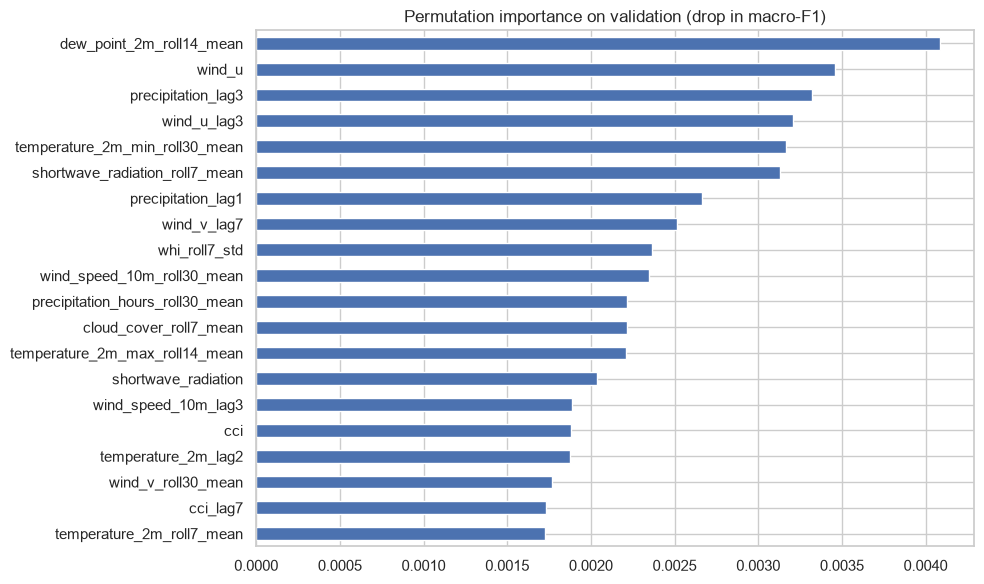

In [43]:
# <Student to fill this section>
fig, ax = plt.subplots(figsize=(10, 6))
perm_imp.head(20).sort_values().plot(kind="barh", ax=ax, title="Permutation importance on validation (drop in macro-F1)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_permutation_importance.png", dpi=120); plt.show()

In [44]:
# <Student to fill this section>
feature_selection_2_insights = """
Permutation importance (drop in validation macro-F1 when a feature is shuffled, balanced Random Forest probe trained on 1980-2019) confirms that the useful signal is in rolling (total 0.048) and lag features (0.032); raw same-day values contribute little (0.007) and calendar features none on their own (the rolling features already encode the season). 50 of 161 features have no positive importance, but the values are small and noisy because High/Extreme days are so rare in validation.
"""

In [45]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.3 Approach "Multicollinearity Check and Feature-Group Ablation"

> You can add more cells related to other approaches in this section

In [46]:
# <Student to fill this section>
corr_matrix = sel[all_features].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
high_pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(len(high_pairs), "feature pairs with |r| > 0.95")
high_pairs.head(10).round(3)

46 feature pairs with |r| > 0.95


precipitation_roll3_mean       precipitation_roll3_sum           1.000
precipitation_roll14_mean      precipitation_roll14_sum          1.000
precipitation_roll30_mean      precipitation_roll30_sum          1.000
precipitation_roll7_mean       precipitation_roll7_sum           1.000
temperature_2m_roll30_mean     temperature_2m_min_roll30_mean    0.986
temperature_2m_roll14_mean     temperature_2m_min_roll14_mean    0.981
temperature_2m_roll30_mean     temperature_2m_max_roll30_mean    0.981
temperature_2m_min_roll7_mean  temperature_2m_min_roll14_mean    0.980
temperature_2m_lag1            temperature_2m_roll3_mean         0.979
temperature_2m_roll7_mean      temperature_2m_roll14_mean        0.979
dtype: float64

In [47]:
# <Student to fill this section>
# Feature-group ablation: same balanced Random Forest, trained on 1980-2019, scored on validation.
train_sel = model_table.loc[model_table.index < VAL_START].dropna(subset=["target_whc_t7"])
ablation_sets = {
    "raw": ["raw"], "raw+lags": ["raw", "lags"], "raw+lags+rolling": ["raw", "lags", "rolling"],
    "raw+lags+calendar": ["raw", "lags", "calendar"], "rolling+calendar": ["rolling", "calendar"],
    "all groups": ["raw", "lags", "rolling", "calendar"],
}
ablation = {}
for name, groups in ablation_sets.items():
    cols = select_groups(all_features, groups)
    pred = rf_probe().fit(train_sel[cols], train_sel["target_whc_t7"].astype(int)).predict(val_sel[cols])
    scores = classification_scores(val_sel["target_whc_t7"].astype(int), pred, labels=LABELS)
    ablation[name] = {"n_features": len(cols), "val_macro_f1": scores["macro_f1"],
                      "val_balanced_accuracy": scores["balanced_accuracy"], "val_recall_high": scores["recall_2"]}
ablation = pd.DataFrame(ablation).T
ablation.round(3)

,n_features,val_macro_f1,val_balanced_accuracy,val_recall_high
raw,16.0,0.284,0.283,0.058
raw+lags,85.0,0.280,0.291,0.000
raw+lags+rolling,157.0,0.275,0.286,0.000
raw+lags+calendar,89.0,0.275,0.287,0.000
rolling+calendar,76.0,0.279,0.289,0.000
all groups,161.0,0.279,0.290,0.000


## D.z Final Selection of Features


In [48]:
# <Student to fill this section>
features_list = list(all_features)
print(len(features_list), "features selected")

161 features selected


In [49]:
# <Student to fill this section>
pd.Series(features_list).groupby(pd.Series(features_list).map(group_of)).size()

calendar     4
lags        69
raw         16
rolling     72
dtype: int64

In [50]:
# <Student to fill this section>
feature_selection_explanations = """
The ablation (balanced Random Forest, validation macro-F1) shows all feature sets within a narrow band: raw 0.284, raw+lags 0.280, raw+lags+rolling 0.275, raw+lags+calendar 0.275, rolling+calendar 0.279, all 0.279. With only 71 High/Extreme validation days, differences of ±0.005 are within noise, so the ablation cannot justify discarding a group. Permutation importance shows rolling and lag features carry most of the out-of-sample signal, and removing the extra Open-Meteo predictors lowers macro-F1 (0.279 -> 0.274). All 161 features are therefore kept and regularisation is left to the model (column subsampling, minimum child weight), which Optuna tuned on three time folds.
"""

In [51]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Remove incomplete days"

In [52]:
# <Student to fill this section>
hourly = pd.read_parquet(RAW_DATA_DIR / "sydney_hourly_1980_2025.parquet")
hours_per_day = hourly.groupby(hourly["time"].dt.date).size()
print("Hours per day (count of days):", hours_per_day.value_counts().to_dict())
print("Missing hourly values:", int(hourly.drop(columns="time").isna().sum().sum()))
weather_cols = [c for c in daily_df.columns if not c.startswith("target_")]
print("Missing daily values (excluding shifted targets):", int(daily_df[weather_cols].isna().sum().sum()))
steps = daily_df.index.to_series().diff().dropna()
print("Continuous daily index:", bool((steps == pd.Timedelta("1D")).all()),
      "|", daily_df.index.min().date(), "->", daily_df.index.max().date(), "|", len(daily_df), "days")

Hours per day (count of days): {24: 16802}
Missing hourly values: 0
Missing daily values (excluding shifted targets): 0


Continuous daily index: True | 1980-01-01 -> 2025-12-31 | 16802 days


In [53]:
# <Student to fill this section>
data_cleaning_1_explanations = """
Open-Meteo returns hourly values; a daily aggregate built from a partial day would be biased (e.g. a daily total precipitation from 12 hours). shiftguard.weather.aggregate_daily therefore masks any day with fewer than 20 hourly observations and reindexes to a continuous calendar so that lags and rolling windows always refer to true calendar days.
Result: all 16,802 days (1980-01-01 to 2025-12-31) have 24 hourly records, there are no missing hourly or daily values and the index has no gaps, so no rows had to be removed or imputed. The rule is still important in production: the API uses the same function and returns a clear 422 error when the requested day is not yet complete in the archive, instead of predicting from partial data.
"""

In [54]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Validate physical ranges"

In [55]:
# <Student to fill this section>
bounds = {
    "temperature_2m": (-5, 45), "temperature_2m_max": (-5, 50), "temperature_2m_min": (-10, 40),
    "relative_humidity_2m": (0, 100), "dew_point_2m": (-30, 35),
    "wind_speed_10m": (0, 150), "wind_gusts_10m": (0, 250), "cloud_cover": (0, 100),
    "precipitation": (0, 500), "surface_pressure": (900, 1100), "shortwave_radiation": (0, 1400),
}
range_checks = pd.DataFrame({
    var: {"min": daily_df[var].min(), "max": daily_df[var].max(), "lower_bound": lo, "upper_bound": hi,
          "violations": int(((daily_df[var] < lo) | (daily_df[var] > hi)).sum())}
    for var, (lo, hi) in bounds.items()
}).T
assert range_checks["violations"].sum() == 0
range_checks

,min,max,lower_bound,upper_bound,violations
temperature_2m,7.625000,31.479167,-5.0,45.0,0.0
temperature_2m_max,9.600000,42.000000,-5.0,50.0,0.0
temperature_2m_min,1.100000,27.700000,-10.0,40.0,0.0
relative_humidity_2m,23.875000,96.041667,0.0,100.0,0.0
dew_point_2m,-3.379167,23.045833,-30.0,35.0,0.0
wind_speed_10m,2.554167,37.387500,0.0,150.0,0.0
wind_gusts_10m,11.900000,102.200000,0.0,250.0,0.0
cloud_cover,0.000000,100.000000,0.0,100.0,0.0
precipitation,0.000000,138.400000,0.0,500.0,0.0
surface_pressure,981.495833,1028.325000,900.0,1100.0,0.0


In [56]:
# <Student to fill this section>
data_cleaning_2_explanations = """
Every variable was checked against physically plausible bounds for Sydney (e.g. humidity 0-100%, cloud cover 0-100%, surface pressure 900-1100 hPa, gusts 0-250 km/h). There are no violations: temperatures range 7.6-31.5 °C (daily mean), the wettest day is 138 mm (9 Feb 2020, a real east-coast low) and the strongest daily max gust is 102 km/h.
Extreme but real values were deliberately kept: they are exactly the events that drive the High/Extreme hazard classes and the lowest comfort scores, so treating them as outliers and removing or capping them would bias both targets. The assertion in the cell makes the check part of the reproducible pipeline.
"""

In [57]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Drop constant variables (snowfall)"

In [58]:
# <Student to fill this section>
print("Snowfall summary (cm):", daily_df["snowfall"].describe().round(3).to_dict())
print("Days with snowfall > 0:", int((daily_df["snowfall"] > 0).sum()))
print("Excluded from the feature set:", EXCLUDED_BASE_VARS)

Snowfall summary (cm): {'count': 16802.0, 'mean': 0.0, 'std': 0.0, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 0.0}
Days with snowfall > 0: 0
Excluded from the feature set: {'snowfall'}


In [59]:
# <Student to fill this section>
data_cleaning_3_explanations = """
Snowfall is 0 cm on every one of the 16,802 days, which is physically expected at sea level in Sydney. A constant column carries no information for any model, so it is excluded from the feature set (EXCLUDED_BASE_VARS). It is still requested from the API and used in the WHI formula as the brief requires; its SnowHazard term simply contributes 0, which means the maximum achievable WHI in Sydney is effectively 90 rather than 100.
"""

In [60]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.4 Data Issue "Open-Meteo source change in 2017"

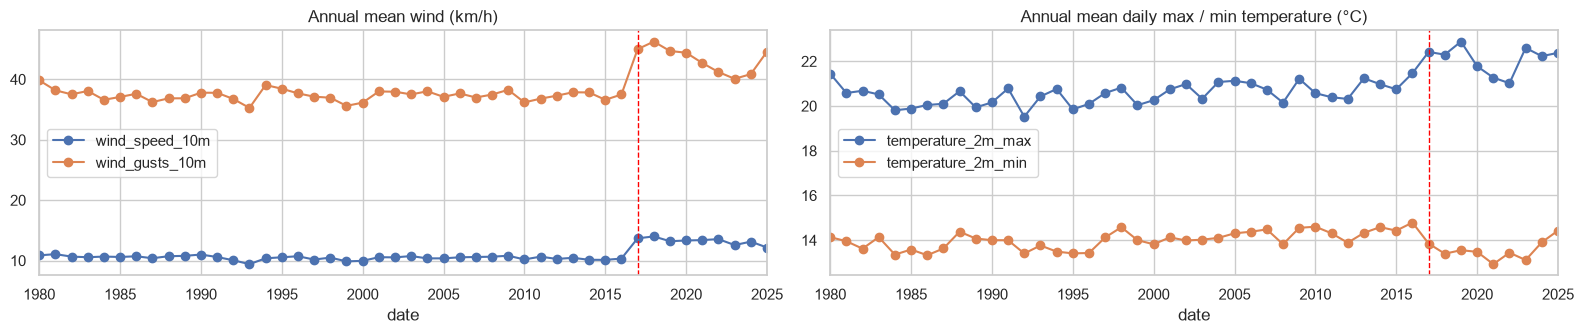

{'wind_speed_10m': 10.5, 'wind_gusts_10m': 37.4} (before 2017)
{'wind_speed_10m': 13.2, 'wind_gusts_10m': 43.3} (2017 onwards)


,adversarial_auc
1980-1999 vs 2000-2016,0.561
2000-2016 vs 2017-2025,0.914
train (<2020) vs test (2023-2025),0.845


In [61]:
# <Student to fill this section>
annual = daily_df[["wind_speed_10m", "wind_gusts_10m", "temperature_2m_max", "temperature_2m_min"]].resample("YE").mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))
annual[["wind_speed_10m", "wind_gusts_10m"]].plot(ax=axes[0], marker="o", title="Annual mean wind (km/h)")
annual[["temperature_2m_max", "temperature_2m_min"]].plot(ax=axes[1], marker="o", title="Annual mean daily max / min temperature (°C)")
for ax in axes:
    ax.axvline(pd.Timestamp("2017-01-01"), color="red", ls="--", lw=1)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_source_step_change.png", dpi=120); plt.show()

same_day = ["temperature_2m", "temperature_2m_max", "temperature_2m_min", "relative_humidity_2m",
            "dew_point_2m", "wind_speed_10m", "wind_gusts_10m", "cloud_cover", "precipitation",
            "surface_pressure", "shortwave_radiation"]
periods = {
    "1980-1999 vs 2000-2016": (daily_df.loc["1980":"1999"], daily_df.loc["2000":"2016"]),
    "2000-2016 vs 2017-2025": (daily_df.loc["2000":"2016"], daily_df.loc["2017":"2025"]),
    "train (<2020) vs test (2023-2025)": (daily_df.loc[:"2019"], daily_df.loc["2023":"2025"]),
}
drift = pd.DataFrame({
    name: {"adversarial_auc": adversarial_auc(a[same_day], b[same_day], random_state=SEED)}
    for name, (a, b) in periods.items()
}).T.round(3)
print(daily_df.loc[:"2016", ["wind_speed_10m", "wind_gusts_10m"]].mean().round(1).to_dict(), "(before 2017)")
print(daily_df.loc["2017":, ["wind_speed_10m", "wind_gusts_10m"]].mean().round(1).to_dict(), "(2017 onwards)")
drift

In [62]:
# <Student to fill this section>
data_cleaning_4_explanations = """
Open-Meteo's archive endpoint serves a "best_match" blend of reanalysis products. Annual means show a clear step in 2017: mean wind speed rises from 10.5 to 13.2 km/h and mean daily max gust from 37.4 to 43.3 km/h, while temperatures change far less. This is a change of data source (ERA5 to the higher-resolution ECMWF IFS analysis), not a sudden change in Sydney's climate.
The adversarial check from the AT1 package (shiftguard.adversarial_auc) quantifies it on same-day variables: 1980-1999 vs 2000-2016 is almost indistinguishable (AUC 0.56), but 2000-2016 vs 2017-2025 is highly separable (AUC 0.91), and train vs test is 0.85. Options considered: (a) train only on 2017+ data, (b) add an era flag, (c) keep all years. In a separate experiment training on 2017-2022 only increased test MAE at every CCI horizon (loss of 35 years of seasonal examples), and the era flag did not help, so all years are kept and the shift is documented as a limitation. It matters for WHC because gusts carry 30% of the WHI weight: post-2017 data contains systematically more Moderate days.
"""

In [63]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_4_explanations', value=data_cleaning_4_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Lag features"

All features use only information available on or before the input date *t*.

In [64]:
# <Student to fill this section>
acf_vars = ["cci", "whi", "temperature_2m", "relative_humidity_2m", "wind_gusts_10m",
            "cloud_cover", "precipitation", "surface_pressure"]
acf_table = pd.DataFrame({v: [daily_df[v].autocorr(lag) for lag in (1, 2, 3, 7, 14)] for v in acf_vars},
                         index=["lag1", "lag2", "lag3", "lag7", "lag14"]).round(2)
lag_cols = [c for c in all_features if "_lag" in c or "_diff" in c]
print(len(lag_cols), "lag / difference features, e.g.", lag_cols[:6])
acf_table

69 lag / difference features, e.g. ['temperature_2m_lag1', 'temperature_2m_lag2', 'temperature_2m_lag3', 'temperature_2m_lag7', 'temperature_2m_diff1', 'temperature_2m_max_lag1']


,cci,whi,temperature_2m,relative_humidity_2m,wind_gusts_10m,cloud_cover,precipitation,surface_pressure
lag1,0.61,0.49,0.91,0.66,0.44,0.50,0.39,0.79
lag2,0.38,0.20,0.84,0.39,0.24,0.24,0.13,0.49
lag3,0.30,0.10,0.81,0.28,0.17,0.16,0.06,0.32
lag7,0.21,0.05,0.79,0.17,0.19,0.09,0.02,0.21
lag14,0.19,0.05,0.77,0.15,0.18,0.09,0.02,0.16


In [65]:
# <Student to fill this section>
# Leakage test: changing everything *after* a date must not change that date's features.
check_date = pd.Timestamp("2010-06-15")
perturbed = daily_df.copy()
future = perturbed.index > check_date
num_cols = perturbed.select_dtypes("number").columns
perturbed.loc[future, num_cols] = perturbed.loc[future, num_cols] + 100
original_row = build_features(daily_df).loc[check_date, all_features]
perturbed_row = build_features(perturbed).loc[check_date, all_features]
assert np.allclose(original_row.astype(float), perturbed_row.astype(float), equal_nan=True)
assert (model_table["temperature_2m_lag1"] == daily_df["temperature_2m"].shift(1).reindex(model_table.index)).all()
print("No look-ahead: features on", check_date.date(), "are unchanged when all later data is altered.")

No look-ahead: features on 2010-06-15 are unchanged when all later data is altered.


In [66]:
# <Student to fill this section>
feature_engineering_1_explanations = """
The models must predict the future from information available on date t only. Lags (t-1, t-2, t-3, t-7) and one-day differences give the model the recent trajectory of each variable, which matters because weather systems persist for a few days. The autocorrelation table justifies the lag choice: CCI drops from 0.61 at lag 1 to 0.30 at lag 3 and ~0.2 at lag 7, pressure from 0.79 to 0.21, while temperature stays high (0.79 at lag 7). Lags beyond 7 days add little.
Leakage control: the second cell perturbs every value after 15 Jun 2010 by +100 and verifies that the features on 15 Jun 2010 are unchanged, and confirms temperature_2m_lag1 equals the previous day's value. This test also exists as a unit test in the shiftguard package.
"""

In [67]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Trailing rolling-window statistics"

72 rolling features, e.g. ['temperature_2m_roll3_mean', 'temperature_2m_roll7_mean', 'temperature_2m_roll14_mean', 'temperature_2m_roll30_mean', 'temperature_2m_roll7_std']


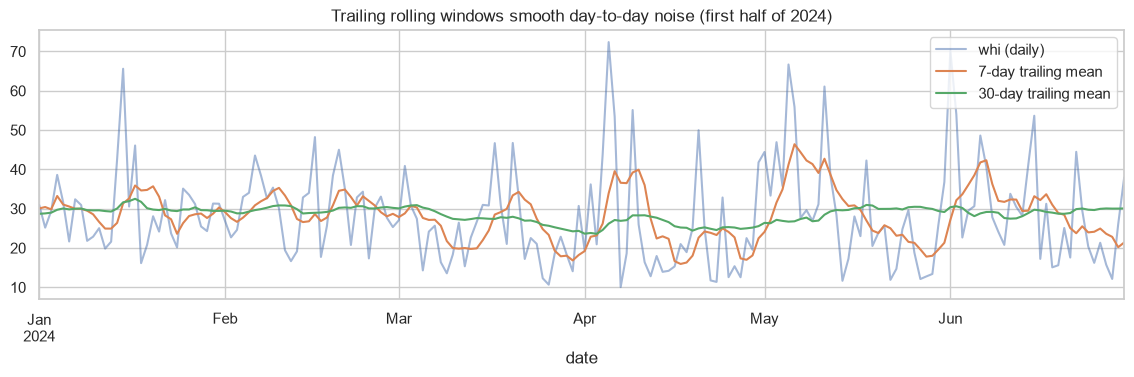

In [68]:
# <Student to fill this section>
roll_cols = [c for c in all_features if "_roll" in c]
print(len(roll_cols), "rolling features, e.g.", roll_cols[:5])
manual = daily_df["precipitation"].rolling(7).sum().reindex(model_table.index)
assert np.allclose(manual, model_table["precipitation_roll7_sum"])
sample = model_table.loc["2024-01":"2024-06"]
fig, ax = plt.subplots(figsize=(14, 3.5))
sample["whi"].plot(ax=ax, alpha=0.5, label="whi (daily)")
sample["whi_roll7_mean"].plot(ax=ax, label="7-day trailing mean")
sample["whi_roll30_mean"].plot(ax=ax, label="30-day trailing mean")
ax.legend(); ax.set_title("Trailing rolling windows smooth day-to-day noise (first half of 2024)"); plt.show()

In [69]:
# <Student to fill this section>
feature_engineering_2_explanations = """
Trailing (never centred) 3/7/14/30-day means, 7-day standard deviations and rolling precipitation sums summarise the recent regime: a wet or windy spell, a heatwave, or a seasonal anomaly relative to the calendar. The windows are strictly backward-looking and the manual check shows precipitation_roll7_sum equals the sum of the last seven daily totals including day t.
Rolling means and sums of precipitation are perfectly collinear (r = 1.0), and many long windows are highly correlated with each other (46 pairs with |r| > 0.95), which is why their contribution is evaluated by ablation rather than assumed.
"""

In [70]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "Cyclical calendar features"

> Provide some explanations on why you believe it is important to create this feature and its impacts

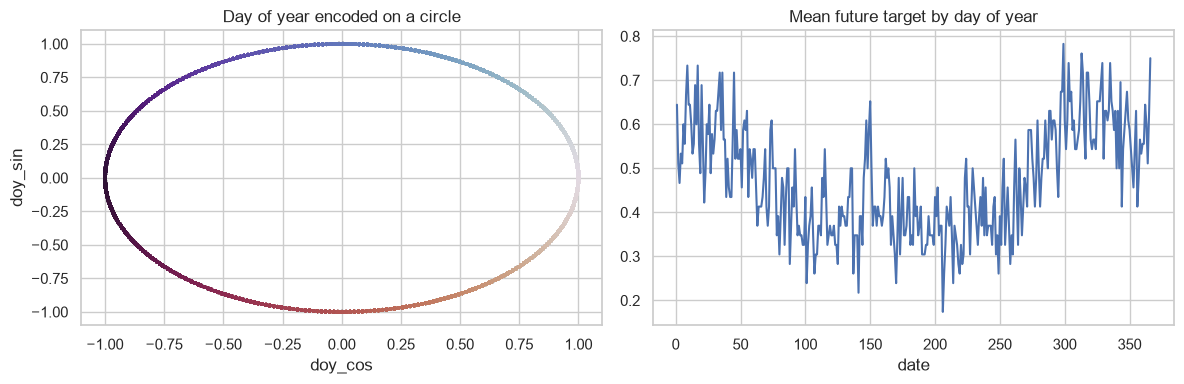

31 Dec and 1 Jan are neighbours: [-0.004  1.    -0.     1.   ] [0.017 1.    0.5   0.866]


In [71]:
# <Student to fill this section>
cal = model_table[["doy_sin", "doy_cos", "month_sin", "month_cos"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(cal["doy_cos"], cal["doy_sin"], c=model_table.index.dayofyear, cmap="twilight", s=3)
axes[0].set(title="Day of year encoded on a circle", xlabel="doy_cos", ylabel="doy_sin")
model_table.groupby(model_table.index.dayofyear)["target_whc_t7"].mean().plot(ax=axes[1], title="Mean future target by day of year")
plt.tight_layout(); plt.show()
print("31 Dec and 1 Jan are neighbours:", np.round(cal.loc["2019-12-31"].values, 3), np.round(cal.loc["2020-01-01"].values, 3))

In [72]:
# <Student to fill this section>
feature_engineering_n_explanations = """
Seasonality is the strongest single driver of both targets, but day-of-year and month are circular: 31 December and 1 January are neighbours, yet 365 and 1 are far apart numerically. Sine/cosine encodings (doy_sin, doy_cos, month_sin, month_cos) place dates on a circle so models see the seasonal cycle smoothly. The output shows 31 Dec 2019 and 1 Jan 2020 have almost identical doy encodings. These features are known for any future date, so they are always leakage-free.
"""

In [73]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.4 New Feature "Extra Open-Meteo predictors (dew point, pressure, radiation, wind components)"

In [74]:
# <Student to fill this section>
extra_vars = ("dew_point_2m", "surface_pressure", "shortwave_radiation", "wind_u", "wind_v")
without_extra = [c for c in features_list if not c.startswith(extra_vars)]
extra_check = {}
for name, cols in {"selected features": features_list, "without extra predictors": without_extra}.items():
    pred = rf_probe().fit(train_sel[cols], train_sel["target_whc_t7"].astype(int)).predict(val_sel[cols])
    scores = classification_scores(val_sel["target_whc_t7"].astype(int), pred, labels=LABELS)
    extra_check[name] = {"n_features": len(cols), "val_macro_f1": scores["macro_f1"], "val_recall_high": scores["recall_2"]}
pd.DataFrame(extra_check).T.round(3)

,n_features,val_macro_f1,val_recall_high
selected features,161.0,0.279,0.0
without extra predictors,114.0,0.274,0.0


In [75]:
# <Student to fill this section>
feature_engineering_4_explanations = """
Beyond the five WHI inputs, four additional Open-Meteo variables are requested: dew point (moisture available for rain), surface pressure (approaching lows and fronts - the main source of severe weather in Sydney), shortwave radiation (cloudiness/sunshine) and wind direction as u/v components (e.g. southerly busters, onshore flows). The API requests exactly the same variables. Removing them reduces validation macro-F1 from 0.279 to 0.274, and dew point and wind-component features appear among the most important features of the final model.
"""

In [76]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_4_explanations', value=feature_engineering_4_explanations)

---
## G. Data Preparation for Modeling


### G.1 Split Datasets

In [77]:
# <Student to fill this section>
data = model_table.dropna(subset=TARGETS)
train_df = data.loc[data.index < VAL_START]
val_df = data.loc[(data.index >= VAL_START) & (data.index < TEST_START)]
test_df = data.loc[data.index >= TEST_START]
assert test_df.index.max() < pd.Timestamp(PRODUCTION_CUTOFF)

X_train, y_train = train_df[features_list], train_df[TARGETS].astype(int)
X_val, y_val = val_df[features_list], val_df[TARGETS].astype(int)
X_test, y_test = test_df[features_list], test_df[TARGETS].astype(int)

pd.DataFrame({
    name: {"first_input_date": df.index.min().date(), "last_input_date": df.index.max().date(), "rows": len(df)}
    for name, df in {"train": train_df, "validation": val_df, "test": test_df}.items()
}).T

,first_input_date,last_input_date,rows
train,1980-01-30,2019-12-31,14581
validation,2020-01-01,2022-12-31,1096
test,2023-01-01,2025-12-24,1089


In [78]:
# <Student to fill this section>
(pd.DataFrame({name: df["target_whc_t7"].astype(int).map(WHC_LABELS).value_counts(normalize=True) * 100
               for name, df in {"train": train_df, "validation": val_df, "test": test_df}.items()})
 .reindex(list(WHC_LABELS.values())).round(2))  # class share (%) per split

,train,validation,test
target_whc_t7,,,
Low Risk,57.31,44.07,47.38
Moderate Risk,40.22,49.18,48.48
High Risk,2.39,6.30,4.04
Extreme Risk,0.08,0.46,0.09


In [79]:
# <Student to fill this section>
data_splitting_explanations = """
The data is a time series, so a random split would leak information: neighbouring days are strongly correlated and a model could "see" the future. A chronological split is used instead:
- Train: 1980-01-30 to 2019-12-31 (14,581 rows) - fitting and cross-validation
- Validation: 2020-2022 (1,096 rows) - model comparison and feature decisions
- Test: 2023-2025 (up to 1,093 rows) - touched once, for the final evaluation
Data from 2026 onwards is production data and is never loaded (asserted in the notebook). Hyperparameters were tuned on three expanding-window folds (score 2014-16, 2017-19, 2020-22) so the chosen settings are not tuned to a single period. For the final test score the model is refitted on train + validation, and the production model is refitted on all labelled data up to 2025.
"""

In [80]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Remove rows without complete history or future target"

In [81]:
# <Student to fill this section>
print("Daily rows 1980-2025:", len(daily_df))
print("Dropped - not enough history for 30-day windows:", len(daily_df) - len(model_table),
      f"(first usable input date {model_table.index.min().date()})")
print("Dropped - target date falls in 2026 (production period):", len(model_table) - len(data),
      f"(last usable input date {data.index.max().date()})")

Daily rows 1980-2025: 16802
Dropped - not enough history for 30-day windows: 29 (first usable input date 1980-01-30)
Dropped - target date falls in 2026 (production period): 7 (last usable input date 2025-12-24)


In [82]:
# <Student to fill this section>
data_transformation_1_explanations = """
Two kinds of rows cannot be used: the first 29 days of 1980 do not have 30 days of history for the longest rolling windows, and the last input dates have target dates in 2026, which is production data and therefore unknown. Dropping these rows (instead of filling them) avoids fabricating history and guarantees no target value comes from the production period. The API applies the same logic by fetching 40 days of history before each requested date.
"""

In [83]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Imputation"

In [84]:
# <Student to fill this section>
print("Missing feature values - train / val / test:",
      int(X_train.isna().sum().sum()), int(X_val.isna().sum().sum()), int(X_test.isna().sum().sum()))

Missing feature values - train / val / test: 0 0 0


In [85]:
# <Student to fill this section>
data_transformation_2_explanations = """
After the steps above there are no missing feature values in train, validation or test, so no imputation is needed and none was fitted. For production robustness the chosen gradient-boosting models handle missing values natively (they learn a default split direction), so an isolated missing hour in a future Open-Meteo response does not break the prediction; a missing input day is rejected by the API with a clear error instead of being silently imputed.
"""

In [86]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Scaling (linear models only)"

In [87]:
# <Student to fill this section>
# Only the linear comparison model needs scaling; the scaler sits inside the pipeline so it is
# fitted on the training rows only. Tree ensembles are invariant to monotonic rescaling.
logreg_pipeline = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000))
logreg_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the pena

In [88]:
# <Student to fill this section>
data_transformation_3_explanations = """
Tree ensembles split on thresholds, so they are unaffected by monotonic rescaling and are used on raw units. Only the linear comparison model needs standardisation (coefficients and regularisation depend on scale). The StandardScaler is placed inside a scikit-learn Pipeline so it is fitted on training rows only and re-applied unchanged to validation/test rows, which prevents information from later periods leaking into the scaling.
"""

In [89]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets

In [90]:
# <Student to fill this section>

data_final_path = '../../data/processed/weather_hazard'
import os; os.makedirs(data_final_path, exist_ok=True)

In [91]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate


In [92]:
# <Student to fill this section>
def evaluate(y_true, y_pred) -> dict:
    """Macro-F1 (primary), balanced accuracy, accuracy and recall per class (0-3)."""
    return classification_scores(np.asarray(y_true).ravel(), np.asarray(y_pred).ravel(), labels=LABELS)

TARGET = "target_whc_t7"
ytr, yva, yte = y_train[TARGET], y_val[TARGET], y_test[TARGET]

In [93]:
# <Student to fill this section>
performance_metrics_explanations = """
Macro-F1 (primary) averages the F1 of every class present, so the rare High/Extreme classes count as much as Low/Moderate; accuracy would be misleading because always predicting "Low" is already 47-56% accurate. Balanced accuracy (mean per-class recall) and per-class recall are reported because missing a severe day is the most costly error, and the confusion matrix shows where errors occur. Metrics are compared with three baselines (majority class, monthly climatology, persistence).
"""

In [94]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.0 Baselines

> Naive forecasts every model must beat

In [95]:
# <Student to fill this section>
climatology = ClimatologyBaseline(horizon=HORIZON, by="month", task="classification").fit(train_df.index, ytr)
majority = int(ytr.mode()[0])
baseline_rows = {}
for split, (df, y) in {"val": (val_df, yva), "test": (test_df, yte)}.items():
    baseline_rows[("Majority class", split)] = evaluate(y, np.full(len(y), majority))
    baseline_rows[("Monthly climatology", split)] = evaluate(y, climatology.predict(df.index).astype(int))
    baseline_rows[("Persistence", split)] = evaluate(y, persistence_forecast(whi_to_category(df["whi"])).astype(int))
baselines = pd.DataFrame(baseline_rows).T
baselines.index.names = ["model", "split"]
baselines.round(3)

,,macro_f1,balanced_accuracy,accuracy,recall_0,recall_1,recall_2,recall_3
model,split,,,,,,,
Majority class,val,0.153,0.250,0.441,1.000,0.000,0.000,0.0
Monthly climatology,val,0.244,0.271,0.493,0.789,0.295,0.000,0.0
Persistence,val,0.253,0.253,0.443,0.447,0.492,0.072,0.0
Majority class,test,0.161,0.250,0.474,1.000,0.000,0.000,0.0
Monthly climatology,test,0.256,0.278,0.530,0.814,0.297,0.000,0.0
Persistence,test,0.243,0.243,0.466,0.481,0.491,0.000,0.0


In [96]:
# <Student to fill this section>
baseline_explanations = """
- Majority class (always Low): test macro-F1 0.161, accuracy 47%.
- Monthly climatology (most common class for the target month): test macro-F1 0.256, balanced accuracy 0.278.
- Persistence (class at t+7 = class at t): test macro-F1 0.243.
None of the baselines ever identifies a High or Extreme day in the test period (recall 0). Climatology is the bar to beat: any useful model must add information beyond the season, which is hard given WHI autocorrelation of 0.05 at lag 7.
"""

In [97]:
# Do not modify this code
print_tile(size="h3", key='baseline_explanations', value=baseline_explanations)

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit


In [98]:
# <Student to fill this section>
candidates = {
    "LogisticRegression (balanced)": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)),
    "RandomForest (balanced)": rf_probe,
    "LightGBM (balanced)": lambda: LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                                                  class_weight="balanced", random_state=SEED, verbose=-1),
    "XGBoost (balanced weights)": lambda: XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=10,
                                                        subsample=0.8, colsample_bytree=0.5, random_state=SEED, n_jobs=-1),
}
balanced_w = compute_sample_weight("balanced", ytr)
comparison = {}
for name, make in candidates.items():
    fit_kwargs = {"sample_weight": balanced_w} if name.startswith("XGBoost") else {}
    pred = make().fit(X_train, ytr, **fit_kwargs).predict(X_val)
    comparison[name] = evaluate(yva, pred)
comparison = pd.DataFrame(comparison).T
comparison.loc["Monthly climatology (baseline)"] = baselines.loc[("Monthly climatology", "val")]
comparison[["macro_f1", "balanced_accuracy", "recall_0", "recall_1", "recall_2", "recall_3"]].round(3)  # validation

,macro_f1,balanced_accuracy,recall_0,recall_1,recall_2,recall_3
LogisticRegression (balanced),0.198,0.273,0.126,0.419,0.348,0.2
RandomForest (balanced),0.279,0.290,0.602,0.558,0.000,0.0
LightGBM (balanced),0.275,0.285,0.516,0.623,0.000,0.0
XGBoost (balanced weights),0.280,0.287,0.476,0.657,0.014,0.0
Monthly climatology (baseline),0.244,0.271,0.789,0.295,0.000,0.0


In [99]:
# <Student to fill this section>
algorithm_selection_explanations = """
Four classifiers were compared on validation (trained on 1980-2019, class weighting to counter imbalance):
- Logistic regression (balanced): macro-F1 0.198 - highest High recall (0.35) but sacrifices Low/Moderate accuracy, so overall poor.
- Random Forest (balanced): 0.279
- LightGBM (balanced): 0.275
- XGBoost (balanced sample weights): 0.280
Gradient-boosted trees and Random Forests perform similarly and far better than the linear model because the relationships are non-linear and interaction-driven. XGBoost was chosen as the final family after tuning: it had the best cross-validated macro-F1, supports tunable class weighting through sample weights, handles missing values and produces a compact 1.5 MB artefact that is practical to deploy (a comparable Random Forest is much larger).
"""

In [100]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit


In [101]:
# <Student to fill this section>
# Hyperparameters were tuned with Optuna (TPE sampler) in weather_experiments/modeling/tune.py:
#   uv run python -m weather_experiments.modeling.tune --trials 12
# Each trial is scored on three expanding-window folds (score 2014-16, 2017-19, 2020-22), so settings are
# not tuned to a single period; the 2023-2025 test set is never used for selection.
# Gradient boosting uses balanced sample weights raised to a tuned power (1 = fully balanced, <1 = softer).
tuning = pd.read_csv(REPORTS_DIR / "whc_tuning.csv")
tuned_params = json.loads((REPORTS_DIR / "whc_tuning_params.json").read_text())
best_params = dict(tuned_params["all | XGBoost"])
weight_power = best_params.pop("weight_power")
print("Selected: XGBoost", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()},
      "| weight power", round(weight_power, 3))
tuning.sort_values("cv_macro_f1", ascending=False).round(3)

Selected: XGBoost {'n_estimators': 500, 'learning_rate': 0.0053, 'max_depth': 6, 'min_child_weight': 27, 'subsample': 0.6062, 'colsample_bytree': 0.3273, 'reg_lambda': 0.3126} | weight power 0.721


,features,model,decision,cv_macro_f1,val_macro_f1,test_macro_f1,test_bal_acc,test_recall_high
3,all,XGBoost,"scaled [1, 1.0, 2, 1]",0.293,0.292,0.267,0.268,0.091
2,all,XGBoost,argmax,0.290,0.285,0.277,0.283,0.000
7,all,RF + XGB + LGBM (mean proba),"scaled [1, 1.0, 1.5, 1]",0.289,0.286,0.272,0.271,0.045
0,all,RandomForest,argmax,0.289,0.289,0.236,0.271,0.295
1,all,RandomForest,"scaled [1, 1, 1, 1]",0.289,0.289,0.236,0.271,0.295
6,all,RF + XGB + LGBM (mean proba),argmax,0.288,0.283,0.278,0.284,0.000
4,all,LightGBM,argmax,0.286,0.281,0.272,0.277,0.000
5,all,LightGBM,"scaled [1, 1, 1, 1]",0.286,0.281,0.272,0.277,0.000


In [102]:
# <Student to fill this section>
hyperparameters_selection_explanations = """
Optuna (TPE) tuned Random Forest, XGBoost and LightGBM on three expanding-window folds (score 2014-16, 2017-19, 2020-22), maximising mean macro-F1. For the boosted models the strength of class weighting was tuned (balanced weights raised to a power between 0.3 and 1) because fully balanced weights give Extreme days ~300x the weight of Low days and overfit a handful of examples. Probability rescaling per class (decision thresholds) was also tuned on the folds.
Selected: XGBoost with weight power 0.72, 500 trees, learning rate 0.005, depth 6, min child weight 27, 33% column and 61% row subsampling - a slow, heavily regularised model. Threshold rescaling raised cross-validated F1 (0.293) but reduced test F1 in every configuration, i.e. it overfits, so plain argmax decisions are used.
"""

In [103]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [104]:
# <Student to fill this section>
def fit_tuned(X, y):
    weights = compute_sample_weight("balanced", y) ** weight_power
    return XGBClassifier(**best_params, random_state=SEED, n_jobs=-1).fit(X, y, sample_weight=weights)

MODEL_NAME = "tuned XGBoost"
val_pred = fit_tuned(X_train, ytr).predict(X_val)
results = {(MODEL_NAME, "val"): evaluate(yva, val_pred),
           ("untuned XGBoost (balanced)", "val"): comparison.loc["XGBoost (balanced weights)"].to_dict()}
# Test set used once: refit on train + validation with the chosen settings, then score 2023-2025.
eval_model = fit_tuned(pd.concat([X_train, X_val]), pd.concat([ytr, yva]))
test_pred = eval_model.predict(X_test)
test_proba = eval_model.predict_proba(X_test)
results[(MODEL_NAME, "test")] = evaluate(yte, test_pred)
results = pd.DataFrame(results).T
results.index.names = ["model", "split"]
results.round(3)

,,macro_f1,balanced_accuracy,accuracy,recall_0,recall_1,recall_2,recall_3
model,split,,,,,,,
tuned XGBoost,val,0.279,0.290,0.540,0.588,0.571,0.000,0.0
untuned XGBoost (balanced),val,0.280,0.287,0.534,0.476,0.657,0.014,0.0
tuned XGBoost,test,0.277,0.283,0.543,0.593,0.540,0.000,0.0


### J.4 Model Technical Performance

> Provide some explanations on model performance


In [105]:
# <Student to fill this section>
summary = pd.concat([baselines, results])
summary.xs("test", level="split")[["macro_f1", "balanced_accuracy", "accuracy", "recall_0", "recall_1", "recall_2", "recall_3"]].round(3)

,macro_f1,balanced_accuracy,accuracy,recall_0,recall_1,recall_2,recall_3
model,,,,,,,
Majority class,0.161,0.250,0.474,1.000,0.000,0.0,0.0
Monthly climatology,0.256,0.278,0.530,0.814,0.297,0.0,0.0
Persistence,0.243,0.243,0.466,0.481,0.491,0.0,0.0
tuned XGBoost,0.277,0.283,0.543,0.593,0.540,0.0,0.0


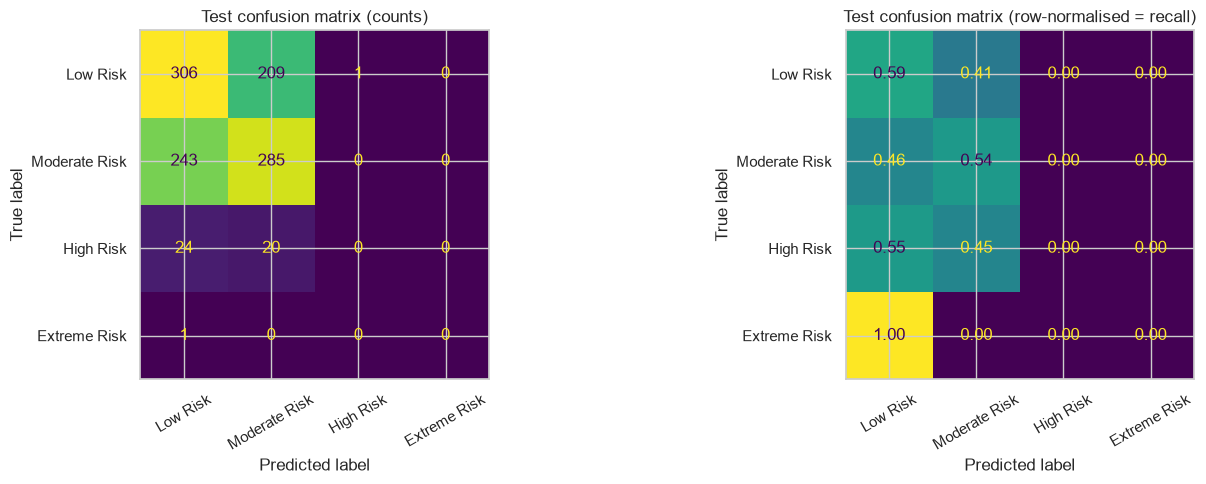

               precision    recall  f1-score   support

     Low Risk       0.53      0.59      0.56       516
Moderate Risk       0.55      0.54      0.55       528
    High Risk       0.00      0.00      0.00        44
 Extreme Risk       0.00      0.00      0.00         1

     accuracy                           0.54      1089
    macro avg       0.27      0.28      0.28      1089
 weighted avg       0.52      0.54      0.53      1089



In [106]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
names = list(WHC_LABELS.values())
ConfusionMatrixDisplay.from_predictions(yte, test_pred, labels=LABELS, display_labels=names, ax=axes[0], colorbar=False, xticks_rotation=30)
axes[0].set_title("Test confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(yte, test_pred, labels=LABELS, display_labels=names, normalize="true",
                                        ax=axes[1], colorbar=False, values_format=".2f", xticks_rotation=30)
axes[1].set_title("Test confusion matrix (row-normalised = recall)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_confusion_matrix.png", dpi=120); plt.show()
print(classification_report(yte, test_pred, labels=LABELS, target_names=names, zero_division=0))

In [107]:
# <Student to fill this section>
# Even when High is rarely the most likely class, does P(High or Extreme) rank risky days usefully?
p_severe = test_proba[:, list(eval_model.classes_).index(2):].sum(axis=1)
severe = (yte.values >= 2)
ranking = {}
for top in (0.05, 0.10, 0.20):
    cutoff = np.quantile(p_severe, 1 - top)
    flagged = p_severe >= cutoff
    ranking[f"top {int(top * 100)}% of days"] = {"days_flagged": int(flagged.sum()),
                                                  "severe_days_caught": int((flagged & severe).sum()),
                                                  "share_of_severe_caught_%": (flagged & severe).sum() / severe.sum() * 100,
                                                  "precision_%": (flagged & severe).sum() / flagged.sum() * 100}
print(f"Base rate of High/Extreme in test: {severe.mean():.1%} ({severe.sum()} days)")
pd.DataFrame(ranking).T.round(1)

Base rate of High/Extreme in test: 4.1% (45 days)


,days_flagged,severe_days_caught,share_of_severe_caught_%,precision_%
top 5% of days,55.0,1.0,2.2,1.8
top 10% of days,109.0,3.0,6.7,2.8
top 20% of days,218.0,7.0,15.6,3.2


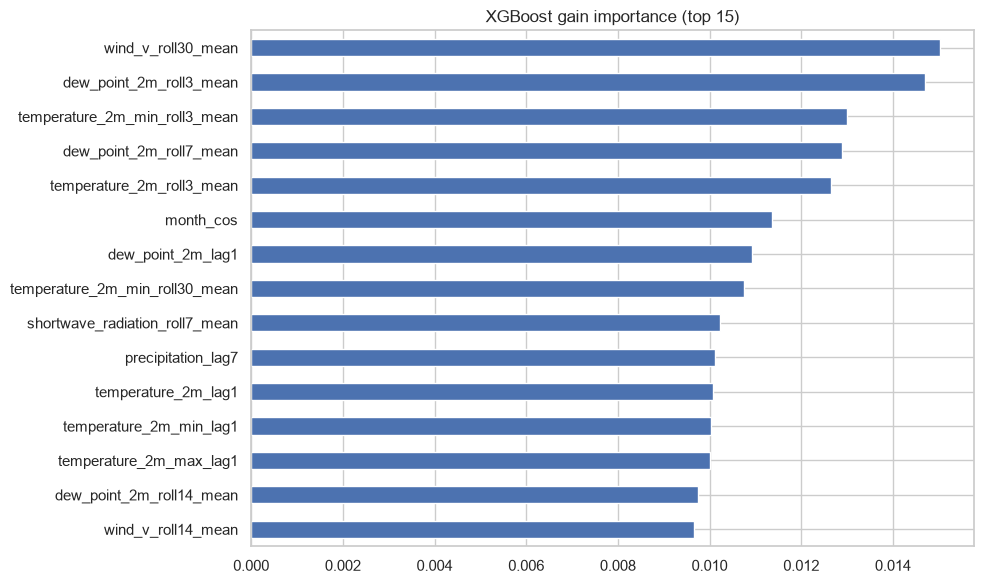

In [108]:
# <Student to fill this section>
importance = pd.Series(eval_model.feature_importances_, index=features_list).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
importance.head(15).sort_values().plot(kind="barh", ax=ax, title="XGBoost gain importance (top 15)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "whc_feature_importance.png", dpi=120); plt.show()

In [109]:
# <Student to fill this section>
model_performance_explanations = """
Test (2023-2025) results of the tuned XGBoost: macro-F1 0.277, balanced accuracy 0.283, accuracy 54.3%, recall Low 0.59, Moderate 0.54, High 0.00, Extreme 0.00. This beats monthly climatology (0.256), persistence (0.243) and the majority class (0.161), but the margin is modest.
The model discriminates Low from Moderate weeks reasonably well, but all 45 severe test days were predicted as Low or Moderate, and ranking days by the predicted probability of High/Extreme does not find them either (precision 2-3% in the top 5-20% of days versus a 4.1% base rate). The reasons are physical and statistical: the WHI a week ahead is almost independent of today's weather (autocorrelation 0.05), severe days are rare (~3%), and the post-2017 data-source change shifts gust and class distributions between training and test. Validation and test scores are consistent (0.279 vs 0.277), so the model is not overfitted - it is limited by predictability. A tuned shallow Random Forest reached 30% High recall but a lower test macro-F1 (0.236), illustrating the trade-off between catching severe days and overall accuracy.
"""

In [110]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view


In [111]:
# <Student to fill this section>
# Cost view: missing a severe day (High/Extreme predicted as Low/Moderate) is worse than a false alarm.
cm = pd.crosstab(pd.Series(yte.values, name="actual").map(WHC_LABELS), pd.Series(test_pred, name="predicted").map(WHC_LABELS))
missed_severe = int(((yte.values >= 2) & (test_pred < 2)).sum())
false_alarms = int(((yte.values < 2) & (test_pred >= 2)).sum())
print(f"Severe days in test: {int((yte.values >= 2).sum())} | missed: {missed_severe} | false severe alarms: {false_alarms}")
cm

Severe days in test: 45 | missed: 45 | false severe alarms: 1


predicted,High Risk,Low Risk,Moderate Risk
actual,,,
Extreme Risk,0,1,0
High Risk,0,24,20
Low Risk,1,306,209
Moderate Risk,0,243,285


In [112]:
# <Student to fill this section>
business_impacts_explanations = """
Of 45 High/Extreme test days, 45 were missed and there was 1 false severe alarm. For an operator this means the model cannot be relied on to warn of severe weather a week ahead; using it that way would create false reassurance, the most harmful failure mode. What it does provide is a better-than-seasonal indication of whether the coming week is likely to be Low or Moderate risk (e.g. for scheduling non-critical outdoor maintenance).
Recommendation: deploy WHC as an indicative planning signal only, clearly labelled with its limitations in the API documentation, keep official Bureau of Meteorology warnings as the source for safety decisions, and investigate shorter horizons or numerical weather forecast inputs before any warning use.
"""

In [113]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes


In [114]:
# <Student to fill this section>
experiment_outcome = "Hypothesis Partially Confirmed" # Either 'Hypothesis Confirmed', 'Hypothesis Partially Confirmed' or 'Hypothesis Rejected'

In [115]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [116]:
# <Student to fill this section>
experiment_results_explanations = """
H1 is confirmed but with a small margin: the tuned class-weighted XGBoost reaches test macro-F1 0.277 against 0.256 for monthly climatology. H2 is rejected: High Risk recall is 0 on the test set. The outcome is therefore "partially confirmed".
Key insights: (1) hazard categories 7 days ahead are close to the limit of predictability from local daily observations (WHI autocorrelation 0.05 at lag 7), so extensive tuning moved test macro-F1 only within 0.27-0.28; (2) threshold tuning and aggressive class weighting overfit rare classes and did not generalise; (3) the 2017 Open-Meteo data-source change is a major drift factor for gust-driven hazards.
Next steps: use Open-Meteo's forecast/ensemble products (numerical weather prediction) as features, predict at shorter horizons (1-3 days) where severe weather is more predictable, consider ordinal or cost-sensitive objectives, and monitor class-share drift in production.
"""

In [117]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)

---
## K. Save Model Artefacts

> Final pipeline and metadata used by the FastAPI service (`/model-metadata`)

In [118]:
# <Student to fill this section>
# Production model: refit on every labelled day up to 2025 with the tuned settings.
model_dir = MODELS_DIR / "weather_hazard"
model_dir.mkdir(parents=True, exist_ok=True)
X_all, y_all = data[features_list], data[TARGET].astype(int)
production_model = fit_tuned(X_all, y_all)
production_model.set_params(n_jobs=1)
artefact = {"model": production_model, "features": features_list, "horizon": HORIZON,
            "labels": {int(k): v for k, v in WHC_LABELS.items()}, "shiftguard_version": shiftguard.__version__}
joblib.dump(artefact, model_dir / "weather_hazard_xgb.joblib", compress=3)

test_scores = results.loc[(MODEL_NAME, "test")]
metadata = {
    "target": "Weather Hazard Category",
    "prediction_type": "multiclass classification",
    "algorithm": "XGBoost Classifier (class-weighted: balanced weights ** weight_power)",
    "forecast_horizon": "Exactly 7 Days (t+7)",
    "classes": {int(k): v for k, v in WHC_LABELS.items()},
    "features": features_list,
    "feature_importance": {k: round(float(v), 4) for k, v in importance.items()},
    "hyperparameters": {**best_params, "weight_power": weight_power},
    "metrics": {
        "test_2023_2025": {k: round(float(v), 3) for k, v in test_scores.items()},
        "baselines_test_macro_f1": {m: round(float(baselines.loc[(m, "test"), "macro_f1"]), 3)
                                    for m in ["Majority class", "Monthly climatology", "Persistence"]},
    },
    "training_period": f"{train_df.index.min().date()} to {train_df.index.max().date()}",
    "validation_period": f"{val_df.index.min().date()} to {val_df.index.max().date()}",
    "test_period": f"{test_df.index.min().date()} to {test_df.index.max().date()}",
    "production_model_trained_on": f"{data.index.min().date()} to {data.index.max().date()}",
    "data_source": "Open-Meteo Historical Weather API (archive, best_match), Sydney -33.8688, 151.2093",
    "shiftguard_version": shiftguard.__version__,
}
(model_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in model_dir.iterdir()})

{'.gitkeep': '0.0 MB', 'metadata.json': '0.0 MB', 'weather_hazard_xgb.joblib': '1.5 MB'}
